# 08_03 The Wasserstein Distance

**Learning objectives**
- Define the **Wasserstein (earth mover's) distance** $W_p$ as the cheapest way to move one distribution's mass onto another, and compute $W_1$ in one dimension from **CDFs** and **quantile functions**.
- Derive $W_2$ between Gaussians, $W_2^2=(\mu_1-\mu_2)^2+(\sigma_1-\sigma_2)^2$, and state the **Kantorovich-Rubinstein duality** for $W_1$.
- Explain why Wasserstein succeeds where **KL and JS fail** (disjoint supports): the **GAN motivation** (WGAN).
- Solve a small **optimal transport** problem with linear programming and use $W_1$ as an interpretable **drift measure**.

**Prerequisites:** [08_02 KL and JS divergence](08_02_kl_js_divergence.ipynb), [02_05 Normal distribution](../../module_02_continuous/notebooks/02_05_normal.ipynb), [05_07 Order statistics](../../module_05_sampling/notebooks/05_07_order_statistics_extremes.ipynb) (empirical CDFs and quantiles).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
The CDF is $F(x)=P(X\le x)$ and the quantile function is $F^{-1}(u)$; if $U\sim\mathrm{Uniform}(0,1)$ then $F^{-1}(U)\sim F$ (inverse-transform sampling). KL and JS (08_02) compare *densities point by point*: they ignore how far apart the places are where the densities differ.

## 3. Intuition and story
Picture the first distribution as a pile of earth and the second as a hole of the same volume. The **Wasserstein distance** is the least work (mass times distance) needed to move the earth into the hole. Two piles that are a metre apart cost one unit of work per unit of earth, whether or not they overlap; two piles a kilometre apart cost a thousand.

KL and JS cannot see this. If two densities do not overlap, KL is infinite and JS is stuck at its ceiling $\ln2$ however far apart the piles are, so a learning algorithm that tries to push one towards the other gets **no direction to move in**. This is exactly the problem of early generative adversarial networks, and the reason for the **Wasserstein GAN**.

## 4. Formal definitions

For distributions $\mu,\nu$ on the real line with a cost $|x-y|^p$:

$$W_p(\mu,\nu)=\Big(\inf_{\gamma\in\Gamma(\mu,\nu)}E_{(X,Y)\sim\gamma}|X-Y|^p\Big)^{1/p},$$

the infimum over all **couplings** $\gamma$ (joint distributions with marginals $\mu$ and $\nu$).

| Fact | Formula |
|---|---|
| **1D, $W_1$ via CDFs** | $W_1=\displaystyle\int_{-\infty}^{\infty}|F(x)-G(x)|\,dx$ |
| **1D, via quantiles** | $W_p^p=\displaystyle\int_0^1|F^{-1}(u)-G^{-1}(u)|^p\,du$ |
| **Gaussians** | $W_2^2\big(N(\mu_1,\sigma_1^2),N(\mu_2,\sigma_2^2)\big)=(\mu_1-\mu_2)^2+(\sigma_1-\sigma_2)^2$ |
| **Location shift** | $W_p(X,X+c)=|c|$ for every $p$ |
| **Kantorovich-Rubinstein** | $W_1(\mu,\nu)=\sup_{\|f\|_{\mathrm{Lip}}\le1}\big(E_\mu f-E_\nu f\big)$ |
| **Samples** | $W_1=\frac1n\sum_i|x_{(i)}-y_{(i)}|$ for equal-size samples (sorted values) |

## 5. Derivations

### 5.1 In one dimension the best plan keeps the order
Moving the smallest piece of earth to the nearest-left part of the hole and so on never crosses two transport paths unnecessarily: crossing paths can be uncrossed to lower the total distance. So the optimal coupling pairs the $u$-quantile of $\mu$ with the $u$-quantile of $\nu$, giving $W_p^p=\int_0^1|F^{-1}(u)-G^{-1}(u)|^pdu$. **In plain words.** To move one pile onto another on a line, sort both and match them in order; the work is the average gap between corresponding quantiles.

### 5.2 $W_1$ is the area between the two CDFs
The area between the graphs of $F$ and $G$ can be sliced either vertically ($\int|F-G|dx$) or horizontally ($\int|F^{-1}-G^{-1}|du$); both are the same region. Hence $W_1=\int|F(x)-G(x)|dx$. **In plain words.** $W_1$ is the shaded area between the two cumulative curves, measured in the units of the variable (dollars, kilometres, degrees).

### 5.3 Gaussians
For $X=\mu_1+\sigma_1Z$ and $Y=\mu_2+\sigma_2Z$ with the same $Z\sim N(0,1)$ (the quantile coupling), $E(X-Y)^2=(\mu_1-\mu_2)^2+(\sigma_1-\sigma_2)^2E[Z^2]+2(\mu_1-\mu_2)(\sigma_1-\sigma_2)E[Z]=(\mu_1-\mu_2)^2+(\sigma_1-\sigma_2)^2$. **In plain words.** Gaussians are compared by the distance between their means and the distance between their standard deviations, a plain Euclidean distance in the $(\mu,\sigma)$ plane. The multivariate version is the **Frechet distance** behind the FID score of image generators.

### 5.4 Duality and why it helps
$W_1=\sup_{f\ 1\text{-Lipschitz}}(E_\mu f-E_\nu f)$: the largest gap in average of a function that cannot change faster than the distance. A critic network restricted to be 1-Lipschitz (weight clipping or a gradient penalty) estimates $W_1$ and, unlike the JS-based discriminator, keeps giving a useful gradient when the two samples are far apart. **In plain words.** Instead of asking "can a classifier tell them apart?" (which is easy and saturates), ask "by how much can a smooth scoring function separate their averages?".

### 5.5 Why KL and JS fail on disjoint supports
Let $p=U(0,1)$ and $q_\theta=U(\theta,1+\theta)$. For $0<\theta<1$ the densities agree on the overlap and are disjoint elsewhere, so $\mathrm{JS}=\theta\ln2$; for $\theta\ge1$ the supports are disjoint and $\mathrm{JS}=\ln2$ (constant), $\mathrm{KL}(p\|q_\theta)=\infty$, while $W_1=\theta$ for every $\theta$. **In plain words.** The JS curve is a plateau, so its slope is zero: a generator starting far from the data receives no signal; the Wasserstein curve is a straight line with slope 1 everywhere.

## 6. Properties and relationships
- **A true metric** on distributions with a finite $p$-th moment (symmetric, triangle inequality); $W_1\le W_2\le\cdots$ (Jensen).
- **Metrizes weak convergence** (plus moments): small $W_p$ means similar shape *and* similar location, unlike KL.
- **Interpretable units:** the units of the variable; $W_1$ between two samples is "the average distance a data point has to move".
- **Bounds:** $W_1\ge|E_\mu X-E_\nu X|$ (take $f(x)=x$); $\mathrm{TV}\cdot d_{\min}\le W_1\le\mathrm{TV}\cdot\mathrm{diam}$ on a bounded set.
- **Cost of generality:** in more than one dimension $W_p$ needs optimal transport (linear programming, $O(n^3)$) or approximations (**Sinkhorn** entropic regularisation, sliced Wasserstein).
- **Link to ML and AI:** WGAN and WGAN-GP, FID/Frechet distance, **optimal transport** for domain adaptation, word-mover's distance for documents, drift detection, Wasserstein barycentres, image retrieval (earth mover's distance on histograms).

## 7. Helpers

One-dimensional $W_1$ three ways (CDF area, quantile average, `scipy`) and the Gaussian formulas.

In [2]:
from scipy.stats import wasserstein_distance as wd
def w1_cdf(F, G, lo, hi, n=200_001):
    x = np.linspace(lo, hi, n); return np.trapezoid(np.abs(F(x) - G(x)), x)
def w1_quant(Finv, Ginv, m=200_000):
    u = (np.arange(m) + 0.5) / m; return np.mean(np.abs(Finv(u) - Ginv(u)))
def w2_gauss(m1, s1, m2, s2): return np.sqrt((m1 - m2) ** 2 + (s1 - s2) ** 2)
a = stats.norm(0, 1); b = stats.norm(1.5, 2.0)
print("W1 by CDF area:", w1_cdf(a.cdf, b.cdf, -40, 40), "| by quantiles:", w1_quant(a.ppf, b.ppf)); print("W2 Gaussian formula:", w2_gauss(0, 1, 1.5, 2.0), "| W2 by quantiles:", np.sqrt(np.mean((a.ppf((np.arange(200_000) + 0.5) / 200_000) - b.ppf((np.arange(200_000) + 0.5) / 200_000)) ** 2)))
xs_ = np.random.default_rng(0).normal(0, 1, 5000); ys_ = np.random.default_rng(1).normal(1.5, 2.0, 5000); print("sample W1 (scipy):", wd(xs_, ys_), "| sorted-sample formula:", np.mean(np.abs(np.sort(xs_) - np.sort(ys_))))
assert abs(w1_cdf(a.cdf, b.cdf, -40, 40) - w1_quant(a.ppf, b.ppf)) < 1e-4 and abs(wd(xs_, ys_) - np.mean(np.abs(np.sort(xs_) - np.sort(ys_)))) < 1e-9

W1 by CDF area: 1.558613585798308 | by quantiles: 1.5586129016794914
W2 Gaussian formula: 1.8027756377319946 | W2 by quantiles: 1.8027737880325332
sample W1 (scipy): 1.537466189909304 | sorted-sample formula: 1.5374661899093043


## 8. 2D visuals

### 8.1 The shaded area between two CDFs
$W_1$ between $N(0,1)$ and $N(1.5,2^2)$ is the area between their CDFs (left) and equally the average horizontal gap between their quantiles (right).

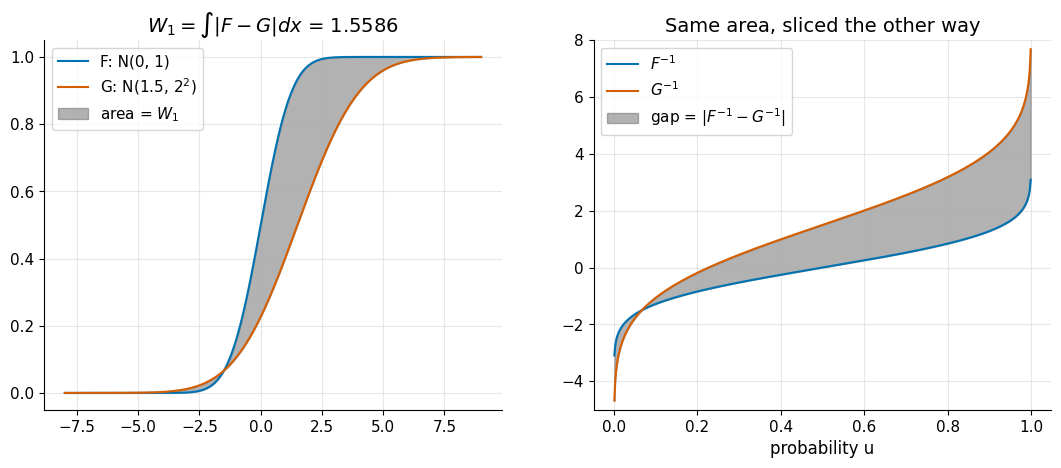

In [3]:
x = np.linspace(-8, 9, 1500); u = np.linspace(0.001, 0.999, 500); fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(x, a.cdf(x), color=MAIN, label="F: N(0, 1)"); axes[0].plot(x, b.cdf(x), color=HIGHLIGHT, label="G: N(1.5, 2$^2$)"); axes[0].fill_between(x, a.cdf(x), b.cdf(x), color=NEUTRAL, alpha=0.5, label="area = $W_1$"); axes[0].legend(); axes[0].set_title(f"$W_1=\\int|F-G|dx$ = {w1_cdf(a.cdf, b.cdf, -40, 40):.4f}")
axes[1].plot(u, a.ppf(u), color=MAIN, label="$F^{-1}$"); axes[1].plot(u, b.ppf(u), color=HIGHLIGHT, label="$G^{-1}$"); axes[1].fill_between(u, a.ppf(u), b.ppf(u), color=NEUTRAL, alpha=0.5, label="gap = $|F^{-1}-G^{-1}|$"); axes[1].set_ylim(-5, 8); axes[1].legend(); axes[1].set_xlabel("probability u"); axes[1].set_title("Same area, sliced the other way")
plt.show(); assert abs(w1_cdf(a.cdf, b.cdf, -40, 40) - 1.5586) < 1e-3

### 8.2 The optimal plan keeps the order
Two samples of 40 points; the optimal matching pairs the sorted values (left), while a random matching crosses and costs more (right).

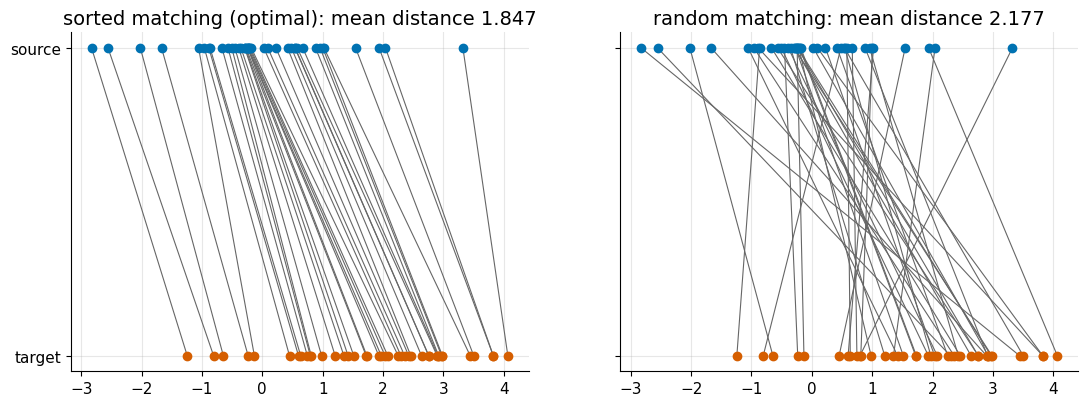

In [4]:
g = np.random.default_rng(3); xa = np.sort(g.normal(0, 1, 40)); ya = np.sort(g.normal(2, 1.3, 40)); perm = g.permutation(40)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (nm, yy) in zip(axes, [("sorted matching (optimal)", ya), ("random matching", ya[perm])]):
    for xi, yi in zip(xa, yy): ax.plot([xi, yi], [1, 0], color=NEUTRAL, linewidth=0.8)
    ax.scatter(xa, np.ones(40), color=MAIN, zorder=3); ax.scatter(yy, np.zeros(40), color=HIGHLIGHT, zorder=3); ax.set_yticks([0, 1]); ax.set_yticklabels(["target", "source"]); ax.set_title(f"{nm}: mean distance {np.mean(np.abs(xa - yy)):.3f}")
plt.show(); cost_sorted = np.mean(np.abs(xa - ya)); cost_rand = np.mean(np.abs(xa - ya[perm])); assert cost_sorted < cost_rand and abs(cost_sorted - wd(xa, ya)) < 1e-12

### 8.3 Distances against the shift: JS plateaus, Wasserstein does not
$p=U(0,1)$ and $q_\theta=U(\theta,1+\theta)$. $\mathrm{JS}=\theta\ln2$ up to $\theta=1$ and then stays at $\ln2$; $\mathrm{KL}(p\|q_\theta)$ is infinite for any $\theta>0$ (not drawn); $W_1=\theta$ for all $\theta$.

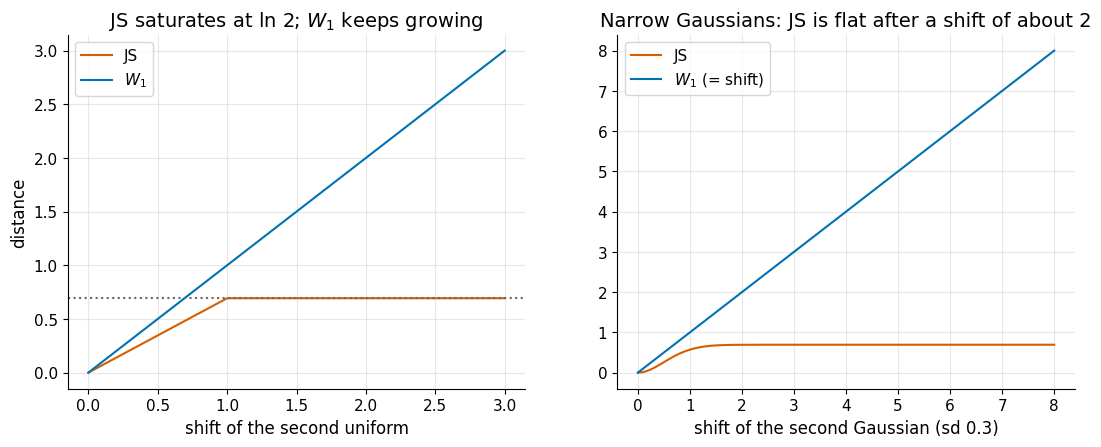

JS at shift 2 and 5 for sd 0.3: 0.691978 0.693147 | ln 2 = 0.693147


In [5]:
th = np.linspace(0, 3, 301); js_u = np.log(2) * np.minimum(th, 1); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(th, js_u, color=HIGHLIGHT, label="JS"); axes[0].plot(th, th, color=MAIN, label="$W_1$"); axes[0].axhline(np.log(2), color=NEUTRAL, linestyle=":"); axes[0].set_xlabel("shift of the second uniform"); axes[0].set_ylabel("distance"); axes[0].legend(); axes[0].set_title("JS saturates at ln 2; $W_1$ keeps growing")
sh2 = np.linspace(0, 8, 200); sig = 0.3; xx = np.linspace(-4, 14, 20_000); f0 = stats.norm.pdf(xx, 0, sig); jsg = []
for t_ in sh2: g_ = stats.norm.pdf(xx, t_, sig); mm = (f0 + g_) / 2; jsg.append(0.5 * np.trapezoid(f0 * np.log(f0 / (mm + 1e-300) + 1e-300), xx) + 0.5 * np.trapezoid(g_ * np.log(g_ / (mm + 1e-300) + 1e-300), xx))
axes[1].plot(sh2, jsg, color=HIGHLIGHT, label="JS"); axes[1].plot(sh2, sh2, color=MAIN, label="$W_1$ (= shift)"); axes[1].set_xlabel("shift of the second Gaussian (sd 0.3)"); axes[1].legend(); axes[1].set_title("Narrow Gaussians: JS is flat after a shift of about 2")
plt.show(); print("JS at shift 2 and 5 for sd 0.3:", round(jsg[50], 6), round(jsg[125], 6), "| ln 2 =", round(np.log(2), 6)); assert abs(jsg[125] - np.log(2)) < 1e-6 and abs(js_u[-1] - np.log(2)) < 1e-12

## 9. 3D visuals

### 9.1 Static: $W_2$ between $N(\mu,\sigma^2)$ and $N(0,1)$
A cone with its apex at $(\mu,\sigma)=(0,1)$: the distance is Euclidean in the $(\mu,\sigma)$ plane, growing linearly (not quadratically as KL does) with the mean shift.

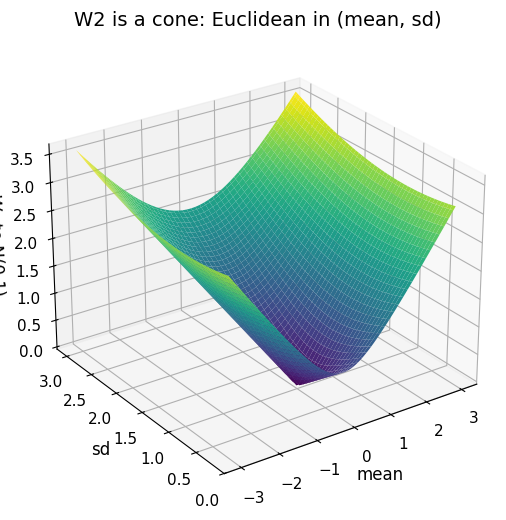

In [6]:
mus = np.linspace(-3, 3, 100); sgs = np.linspace(0.2, 3, 100); M, S = np.meshgrid(mus, sgs); W2s = w2_gauss(M, S, 0, 1)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(M, S, W2s, cmap="viridis", edgecolor="none"); ax.set_xlabel("mean"); ax.set_ylabel("sd"); ax.set_zlabel("$W_2$ to N(0,1)"); ax.set_title("W2 is a cone: Euclidean in (mean, sd)"); ax.view_init(elev=26, azim=-125)
plt.show(); assert W2s.min() < 0.05 and abs(w2_gauss(3, 1, 0, 1) - 3) < 1e-12

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=mus, y=sgs, z=W2s, colorscale="Viridis")); fig.update_layout(title="W2(N(mu, s^2), N(0,1))", width=760, height=560, scene=dict(xaxis_title="mean", yaxis_title="sd", zaxis_title="W2")); fig.show()

### 9.3 Static: $W_1$ between the same Gaussians, computed numerically
$W_1=E|\mu+(\sigma-1)Z|$, a folded-normal expectation; it is smaller than $W_2$ everywhere ($W_1\le W_2$) and equal to $|\mu|$ when $\sigma=1$.

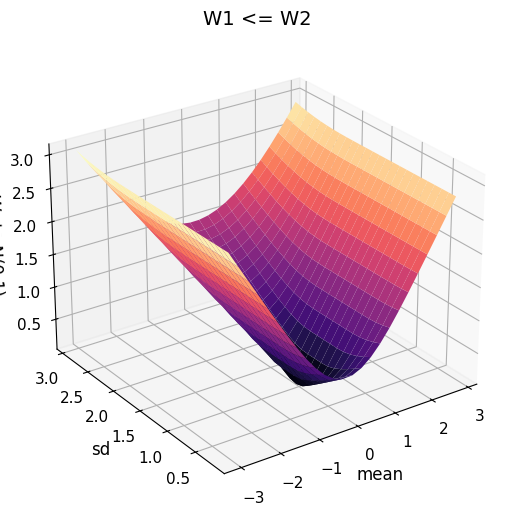

largest ratio W1 / W2 on the grid: 1.0


In [8]:
z = stats.norm.ppf((np.arange(40_000) + 0.5) / 40_000); W1s = np.array([[np.mean(np.abs(m + (s - 1) * z)) for m in mus[::4]] for s in sgs[::4]]); Mm, Ss = np.meshgrid(mus[::4], sgs[::4])
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Mm, Ss, W1s, cmap="magma", edgecolor="none"); ax.set_xlabel("mean"); ax.set_ylabel("sd"); ax.set_zlabel("$W_1$ to N(0,1)"); ax.set_title("W1 <= W2"); ax.view_init(elev=26, azim=-125)
plt.show(); W2c = w2_gauss(Mm, Ss, 0, 1); print("largest ratio W1 / W2 on the grid:", float((W1s / np.maximum(W2c, 1e-9))[W2c > 0.2].max().round(4))); assert (W1s <= W2c + 1e-3).all()

## 10. Simulation vs theory

### 10.1 The sample $W_1$ converges to the population value
For $N(0,1)$ against $N(1.5,2^2)$ the population value is 1.5586. The sample $W_1$ from $n$ points per sample converges at about $n^{-1/2}$; when both samples come from the same distribution it converges to 0 at the same rate.

In [9]:
rows = []; g = np.random.default_rng(4)
for n in (50, 200, 1000, 5000):
    w_d = [wd(g.normal(0, 1, n), g.normal(1.5, 2, n)) for _ in range(300)]; w_0 = [wd(g.normal(0, 1, n), g.normal(0, 1, n)) for _ in range(300)]; rows.append((n, np.mean(w_d), np.std(w_d), np.mean(w_0)))
print(pd.DataFrame(rows, columns=["n per sample", "mean W1 (different)", "SD", "mean W1 (same distribution)"]).round(4).to_string(index=False)); true_w1 = w1_cdf(a.cdf, b.cdf, -40, 40)
assert abs(rows[-1][1] - true_w1) < 0.05 and rows[-1][3] < rows[0][3] / 5 and abs(rows[-1][3] * np.sqrt(5000) - rows[0][3] * np.sqrt(50)) < 0.25

 n per sample  mean W1 (different)     SD  mean W1 (same distribution)
           50               1.5776 0.2604                       0.2338
          200               1.5632 0.1517                       0.1266
         1000               1.5623 0.0657                       0.0587
         5000               1.5592 0.0280                       0.0261


### 10.2 The dual bound
Every 1-Lipschitz function $f$ gives a lower bound $E_\mu f-E_\nu f\le W_1$. Try several; the supremum is reached by $f(x)=\mathrm{sign}$-type functions that follow the difference of the CDFs.

In [10]:
g = np.random.default_rng(5); X = g.normal(0, 1, 400_000); Y = g.normal(1.5, 2, 400_000)
fs = {"x": lambda t: t, "-|x - 1|": lambda t: -np.abs(t - 1), "clip(x, -1, 1)": lambda t: np.clip(t, -1, 1), "sin(x)": np.sin, "-|x|": lambda t: -np.abs(t)}
rowsd = {k: abs(f(X).mean() - f(Y).mean()) for k, f in fs.items()}
xg_ = np.linspace(-12, 14, 4001); Fopt = np.concatenate([[0], np.cumsum(np.sign(b.cdf(xg_[:-1]) - a.cdf(xg_[:-1])) * np.diff(xg_))]); fopt = lambda t: np.interp(t, xg_, Fopt); rowsd["optimal 1-Lipschitz"] = abs(fopt(X).mean() - fopt(Y).mean())
print({k: round(v, 4) for k, v in rowsd.items()}, "| W1 =", round(true_w1, 4)); assert all(v <= true_w1 + 0.01 for v in rowsd.values()) and abs(rowsd["optimal 1-Lipschitz"] - true_w1) < 0.02

{'x': np.float64(1.4997), '-|x - 1|': np.float64(0.4834), 'clip(x, -1, 1)': np.float64(0.5266), 'sin(x)': np.float64(0.1318), '-|x|': np.float64(1.2286), 'optimal 1-Lipschitz': np.float64(1.5596)} | W1 = 1.5586


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("1D W1 between samples: scipy.stats.wasserstein_distance(x, y) | weighted: wasserstein_distance(u_values, v_values, u_weights, v_weights)")
print("W1 from CDFs: np.trapezoid(np.abs(F(x) - G(x)), x) | sorted samples (equal sizes): np.mean(np.abs(np.sort(x) - np.sort(y)))")
print("Gaussians: np.sqrt((m1 - m2)**2 + (s1 - s2)**2) | any p: W_p from quantile functions, np.mean(np.abs(F.ppf(u) - G.ppf(u)) ** p) ** (1 / p)")
print("energy distance (a relative): scipy.stats.energy_distance(x, y) | general transport: scipy.optimize.linprog on the flow matrix (Example 3), POT library for Sinkhorn")
print("check:", wd([0, 1, 3], [5, 6, 8]), "= mean sorted gap", np.mean(np.abs(np.array([0, 1, 3]) - np.array([5, 6, 8]))), "| energy_distance:", stats.energy_distance(xs_, ys_))
assert wd([0, 1, 3], [5, 6, 8]) == 5.0

1D W1 between samples: scipy.stats.wasserstein_distance(x, y) | weighted: wasserstein_distance(u_values, v_values, u_weights, v_weights)
W1 from CDFs: np.trapezoid(np.abs(F(x) - G(x)), x) | sorted samples (equal sizes): np.mean(np.abs(np.sort(x) - np.sort(y)))
Gaussians: np.sqrt((m1 - m2)**2 + (s1 - s2)**2) | any p: W_p from quantile functions, np.mean(np.abs(F.ppf(u) - G.ppf(u)) ** p) ** (1 / p)
energy distance (a relative): scipy.stats.energy_distance(x, y) | general transport: scipy.optimize.linprog on the flow matrix (Example 3), POT library for Sinkhorn
check: 5.0 = mean sorted gap 5.0 | energy_distance: 0.9615842279132537


## 12. Real-world worked examples

---
### Example 1 (main): why GANs moved from JS to Wasserstein

**Scenario.** A generative model has one parameter $\theta$ that shifts its samples. The real data are uniform on $[0,1]$; the generator produces uniform on $[\theta,1+\theta]$. We start at $\theta=5$ and want to reach $\theta=0$.

**Questions**
1. For $\theta=0.5,1,2,5$ give $W_1$, JS and $\mathrm{KL}(p\|q_\theta)$.
2. What are the gradients of JS and of $W_1$ with respect to $\theta$ at $\theta=2$ and $\theta=5$? What happens to gradient descent started at $\theta=5$ with each loss?
3. Repeat the picture for narrow Gaussians (sd 0.3): at what shift is JS within 1 % of $\ln2$?
4. Check $W_1$ by simulation with 20,000 samples per distribution.

### 12.1 By hand
**Q1.** $W_1=\theta$: 0.5, 1, 2, 5. $\mathrm{JS}=\theta\ln2$ for $\theta\le1$ (0.347 at 0.5; 0.693 at 1) and $\ln2=0.693$ for $\theta\ge1$; $\mathrm{KL}(p\|q_\theta)=\infty$ for every $\theta>0$ (there are points where $p>0$ and $q=0$). **Q2.** $dW_1/d\theta=1$ everywhere; $d\mathrm{JS}/d\theta=0$ for $\theta>1$, so JS gives no information about which way to move. **Q3.** two $N(0,0.3^2)$ densities shifted by $\theta$ have JS $\to\ln2$ as $\theta\gg\sigma$; the 1 % level is reached at a shift of a few standard deviations (computed below).

In [12]:
th4 = np.array([0.5, 1.0, 2.0, 5.0]); tab = pd.DataFrame({"W1": th4, "JS": np.log(2) * np.minimum(th4, 1), "KL(p||q)": [np.inf] * 4}, index=[f"theta = {t}" for t in th4]); print(tab.round(4).to_string())
jsf = lambda t: np.log(2) * min(t, 1.0); eps = 1e-4; print("finite-difference gradients: JS at theta = 2:", (jsf(2 + eps) - jsf(2 - eps)) / (2 * eps), "at 5:", (jsf(5 + eps) - jsf(5 - eps)) / (2 * eps), "| W1 at 2 and 5:", (2 + eps - (2 - eps)) / (2 * eps), "and 1")
def js_g(t_, s_=0.3):
    xg = np.linspace(-4 * s_ - 1, t_ + 4 * s_ + 1, 40_000); f = stats.norm.pdf(xg, 0, s_); h = stats.norm.pdf(xg, t_, s_); m = (f + h) / 2; return 0.5 * np.trapezoid(f * np.log(f / (m + 1e-300) + 1e-300), xg) + 0.5 * np.trapezoid(h * np.log(h / (m + 1e-300) + 1e-300), xg)
from scipy.optimize import brentq
t99 = brentq(lambda t_: js_g(t_) - 0.99 * np.log(2), 0.2, 3); print(f"Q3: JS reaches 99% of ln 2 at a shift of {t99:.3f} = {t99 / 0.3:.2f} standard deviations; JS at shift 5: {js_g(5):.6f}")
th_ = 5.0; th_w = 5.0
for _ in range(100): th_ -= 0.1 * (jsf(th_ + eps) - jsf(th_ - eps)) / (2 * eps); th_w -= 0.1 * np.sign(th_w)
print(f"gradient descent from theta = 5, 100 steps of 0.1: JS loss ends at {th_:.3f}; W1 loss ends at {th_w:.3f}")
g = np.random.default_rng(31); xr = g.uniform(0, 1, 20_000); print("Q4: sample W1 at theta = 2 and 5:", round(wd(xr, g.uniform(2, 3, 20_000)), 4), round(wd(xr, g.uniform(5, 6, 20_000)), 4))

              W1      JS  KL(p||q)
theta = 0.5  0.5  0.3466       inf
theta = 1.0  1.0  0.6931       inf
theta = 2.0  2.0  0.6931       inf
theta = 5.0  5.0  0.6931       inf
finite-difference gradients: JS at theta = 2: 0.0 at 5: 0.0 | W1 at 2 and 5: 1.000000000001 and 1
Q3: JS reaches 99% of ln 2 at a shift of 1.688 = 5.63 standard deviations; JS at shift 5: 0.693147
gradient descent from theta = 5, 100 steps of 0.1: JS loss ends at 5.000; W1 loss ends at 0.000


Q4: sample W1 at theta = 2 and 5:

 1.9992 4.9968


### 12.2 Asserts

In [13]:
assert abs((jsf(2 + eps) - jsf(2 - eps)) / (2 * eps)) < 1e-12 and abs((jsf(0.5 + eps) - jsf(0.5 - eps)) / (2 * eps) - np.log(2)) < 1e-9
assert abs(th_ - 5.0) < 1e-12 and abs(th_w) < 0.1 and abs(js_g(5) - np.log(2)) < 1e-6 and 1.6 < t99 < 1.8
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The sample $W_1$ for $U(0,1)$ against $U(\theta,1+\theta)$ equals $\theta$ (the sorted-sample formula is exact for a pure shift).

In [14]:
for t_ in (0.5, 1.0, 2.0, 5.0):
    est = np.mean([wd(g.uniform(0, 1, 20_000), g.uniform(t_, 1 + t_, 20_000)) for _ in range(20)]); print(f"theta = {t_}: sample W1 {est:.4f}"); assert abs(est - t_) < 0.01

theta = 0.5: sample W1 0.4999


theta = 1.0: sample W1 1.0012


theta = 2.0: sample W1 1.9999


theta = 5.0: sample W1 5.0001


### 12.4 Plots

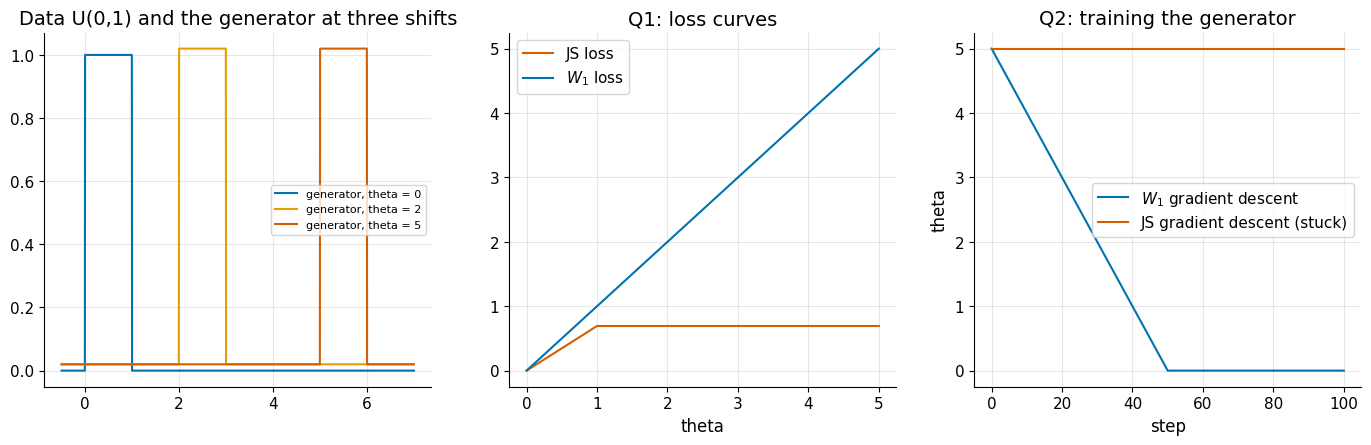

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); xp = np.linspace(-0.5, 7, 1500)
for t_, colr in zip((0, 2, 5), (MAIN, SIM, HIGHLIGHT)): axes[0].plot(xp, ((xp >= t_) & (xp <= 1 + t_)).astype(float) * 1.0 + (0.02 * (t_ > 0)), color=colr, label=f"generator, theta = {t_}")
axes[0].legend(fontsize=8); axes[0].set_title("Data U(0,1) and the generator at three shifts")
tt = np.linspace(0, 5, 501); axes[1].plot(tt, np.log(2) * np.minimum(tt, 1), color=HIGHLIGHT, label="JS loss"); axes[1].plot(tt, tt, color=MAIN, label="$W_1$ loss"); axes[1].set_xlabel("theta"); axes[1].legend(); axes[1].set_title("Q1: loss curves")
st = np.arange(0, 101); axes[2].plot(st, 5 - np.minimum(0.1 * st, 5), color=MAIN, label="$W_1$ gradient descent"); axes[2].plot(st, np.full(st.size, 5.0), color=HIGHLIGHT, label="JS gradient descent (stuck)"); axes[2].set_xlabel("step"); axes[2].set_ylabel("theta"); axes[2].legend(); axes[2].set_title("Q2: training the generator")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- For the uniform generator $W_1=\theta$ (0.5, 1, 2, 5), while JS is $0.347$ at $\theta=0.5$ and exactly $\ln2=0.693$ for every $\theta\ge1$; $\mathrm{KL}(p\|q_\theta)=\infty$ for every $\theta>0$. The finite-difference gradient of JS is **0.0 at $\theta=2$ and at $\theta=5$**, whereas the gradient of $W_1$ is **1.0** at both.
- Gradient descent from $\theta=5$ (100 steps of 0.1) leaves the JS loss **stuck at 5.000** (no gradient) and brings the $W_1$ loss to **0.000**: a generator trained against JS has no signal until the supports touch.
- Narrow Gaussians (sd 0.3) behave the same way up to rounding: JS reaches 99 % of $\ln2$ at a shift of **1.69 (5.6 standard deviations)** and equals 0.693147 at a shift of 5. The sample $W_1$ with 20,000 points per distribution is 1.9992 at $\theta=2$ and 4.9968 at $\theta=5$ (theory 2 and 5).
- **Decision.** When a model must be trained to move one distribution towards another that may initially not overlap (GANs, domain adaptation, distribution matching), use a loss with a distance-aware gradient such as $W_1$; use KL or JS to *evaluate* distributions that already overlap.

---
### Example 2: a drift measure in dollars

**Scenario.** Card transactions follow a lognormal distribution (log-mean 3.5, log-sd 0.8). A fraud monitor compares 1,000 live transactions with a 20,000-transaction training reference. After a promotion the true log-mean rises by 0.15 (amounts about 16 % larger).

**Questions.** (1) What are the sample $W_1$ (in dollars) and the PSI on 10 decile bins, with and without the shift? (2) How large is $W_1$ between two *same-distribution* samples of this size (the noise floor), and is the shifted $W_1$ above it (permutation test)? (3) A 95 % bootstrap interval for $W_1$.

Q1: W1 no shift $1.978, shifted $7.661 | PSI no shift 0.0068, shifted 0.0421 | mean transaction $46.00


population W1 of the shift (1,000,000 points each): $7.312


Q2: permutation noise floor (mean $2.049, 95th percentile $3.276); observed $7.829, permutation p = 0.0025


Q3: bootstrap 95% interval for W1: ($5.013, $10.709)


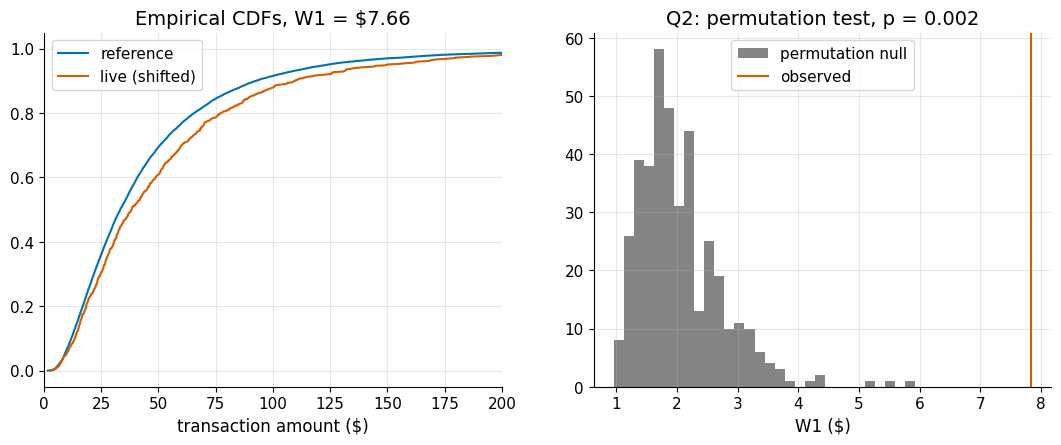

In [16]:
g = np.random.default_rng(32); ref = g.lognormal(3.5, 0.8, 20_000); live0 = g.lognormal(3.5, 0.8, 1000); live1 = g.lognormal(3.65, 0.8, 1000)
edges = np.quantile(ref, np.linspace(0, 1, 11)[1:-1]); psi = lambda a_, b_: (lambda p_, q_: np.sum((q_ - p_) * np.log(q_ / p_)))(np.bincount(np.searchsorted(edges, a_), minlength=10) / a_.size, np.bincount(np.searchsorted(edges, b_), minlength=10) / b_.size)
W0, W1v = wd(ref, live0), wd(ref, live1); print(f"Q1: W1 no shift ${W0:.3f}, shifted ${W1v:.3f} | PSI no shift {psi(ref, live0):.4f}, shifted {psi(ref, live1):.4f} | mean transaction ${ref.mean():.2f}")
pop_w1 = wd(g.lognormal(3.5, 0.8, 1_000_000), g.lognormal(3.65, 0.8, 1_000_000)); print(f"population W1 of the shift (1,000,000 points each): ${pop_w1:.3f}")
pool = np.concatenate([ref[:5000], live1]); null_w = []
for _ in range(400): pp_ = g.permutation(pool); null_w.append(wd(pp_[:5000], pp_[5000:]))
obs5 = wd(ref[:5000], live1); pperm = (np.sum(np.array(null_w) >= obs5) + 1) / (len(null_w) + 1); print(f"Q2: permutation noise floor (mean ${np.mean(null_w):.3f}, 95th percentile ${np.quantile(null_w, 0.95):.3f}); observed ${obs5:.3f}, permutation p = {pperm:.4f}")
boots = [wd(ref, g.choice(live1, 1000)) for _ in range(500)]; lo, hi = np.quantile(boots, [0.025, 0.975]); print(f"Q3: bootstrap 95% interval for W1: (${lo:.3f}, ${hi:.3f})")
assert W1v > W0 and abs(W1v - pop_w1) < 3.0 and pperm < 0.05 and lo < W1v < hi and np.mean(null_w) < W1v
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); xq = np.linspace(0, 200, 800); axes[0].plot(np.sort(ref), np.linspace(0, 1, ref.size), color=MAIN, label="reference"); axes[0].plot(np.sort(live1), np.linspace(0, 1, live1.size), color=HIGHLIGHT, label="live (shifted)"); axes[0].set_xlim(0, 200); axes[0].legend(); axes[0].set_xlabel("transaction amount ($)"); axes[0].set_title(f"Empirical CDFs, W1 = ${W1v:.2f}")
axes[1].hist(null_w, bins=30, color=NEUTRAL, alpha=0.8, label="permutation null"); axes[1].axvline(obs5, color=HIGHLIGHT, label="observed"); axes[1].set_xlabel("W1 ($)"); axes[1].legend(); axes[1].set_title(f"Q2: permutation test, p = {pperm:.3f}")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- With no shift the sample $W_1$ is **1.98 dollars** (the noise floor: two samples of this size from one distribution never match exactly) and the PSI is 0.0068; with the 16 % larger amounts the sample $W_1$ is **7.66 dollars** (population value 7.31 dollars, the mean transaction being 46.00 dollars) and the PSI is 0.0421.
- The permutation null has mean 2.05 dollars and a 95th percentile of 3.28 dollars; the observed 7.83 dollars (reference subsample of 5,000) gives a permutation p-value of **0.0025** (the smallest possible with 400 permutations is 0.0025). The bootstrap 95 % interval for $W_1$ is **(5.01 dollars, 10.71 dollars)**.
- Unlike the PSI, whose size (0.04) means little without a convention, $W_1$ says that a typical live transaction has moved by about **\$7**, 17 % of the average amount. A smaller shift (a 5 % rise of the amounts, tried while building this example) was **not** detectable with 1,000 live transactions: its permutation p-value was 0.08. Detectability depends on the sample size, not only on the metric.
- **Decision.** Report $W_1$ in the units of the variable, alongside a permutation or bootstrap interval; alert when it clearly exceeds the noise floor of that sample size.

---
### Example 3: shipping stock at minimum cost (optimal transport by linear programming)

**Scenario.** Five warehouses on a highway at kilometre 0, 10, 25, 40 and 60 hold 30, 20, 25, 15 and 10 pallets. Five shops at kilometre 5, 20, 30, 50 and 70 need 15, 25, 20, 25 and 15 pallets (100 pallets in total). Shipping costs one unit per pallet per kilometre.

**Questions.** (1) What is the cheapest shipping plan and its cost? (2) Check it against $100\cdot\int|F-G|\,dx$ (the one-dimensional formula). (3) How much more does a plan cost that splits every warehouse's stock across the shops in proportion to demand?

[[15. 15.  0.  0.  0.]
 [ 0. 10. 10.  0.  0.]
 [ 0.  0. 10. 10.  5.]
 [ 0.  0.  0. 15.  0.]
 [ 0.  0.  0.  0. 10.]]
Q1: minimum cost 1450.0 pallet-km | Q2: 100 * area between the CDFs 1450.0; scipy wasserstein_distance * 100 = 1450.0 | Q3: proportional split costs 2595.0 (+79%)


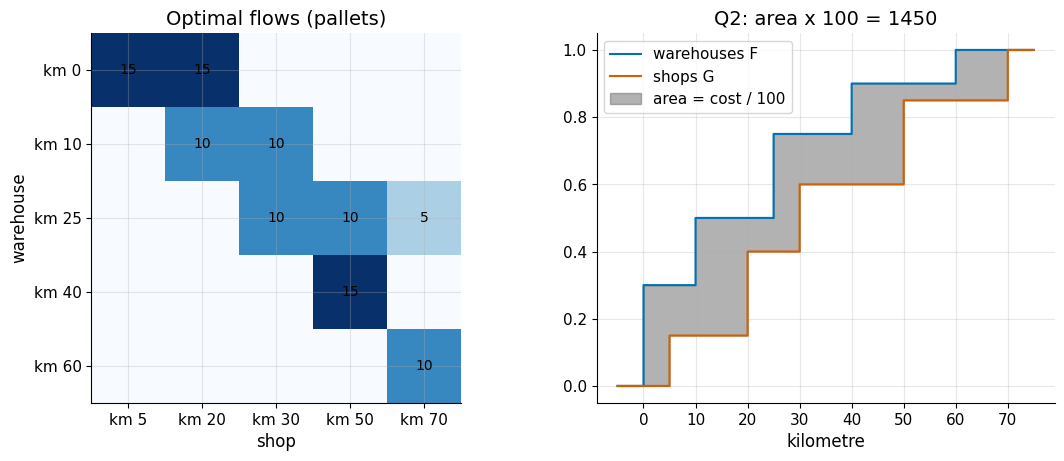

In [17]:
from scipy.optimize import linprog
xw = np.array([0, 10, 25, 40, 60.0]); sw = np.array([30, 20, 25, 15, 10.0]); xs_ = np.array([5, 20, 30, 50, 70.0]); ds = np.array([15, 25, 20, 25, 15.0]); C = np.abs(xw[:, None] - xs_[None, :])
A_eq = np.zeros((10, 25));
for i in range(5): A_eq[i, i * 5:(i + 1) * 5] = 1
for j in range(5): A_eq[5 + j, j::5] = 1
res_ = linprog(C.ravel(), A_eq=A_eq, b_eq=np.concatenate([sw, ds]), bounds=(0, None), method="highs"); plan = res_.x.reshape(5, 5); cost = res_.fun
Fw = lambda t: np.array([sw[xw <= v].sum() for v in np.atleast_1d(t)]) / 100; Gs = lambda t: np.array([ds[xs_ <= v].sum() for v in np.atleast_1d(t)]) / 100; xgrid = np.linspace(-1, 71, 720_001); cost_1d = 100 * np.trapezoid(np.abs(Fw(xgrid[::50]) - Gs(xgrid[::50])), xgrid[::50])
prop = np.outer(sw, ds) / 100; cost_prop = (prop * C).sum(); print(np.round(plan, 1)); print(f"Q1: minimum cost {cost:.1f} pallet-km | Q2: 100 * area between the CDFs {cost_1d:.1f}; scipy wasserstein_distance * 100 = {100 * wd(xw, xs_, sw, ds):.1f} | Q3: proportional split costs {cost_prop:.1f} (+{100 * (cost_prop / cost - 1):.0f}%)")
assert abs(cost - 100 * wd(xw, xs_, sw, ds)) < 1e-6 and abs(cost - cost_1d) < 0.5 and cost_prop > cost and np.allclose(plan.sum(axis=1), sw) and np.allclose(plan.sum(axis=0), ds)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); im = axes[0].imshow(plan, cmap="Blues"); axes[0].set_xticks(range(5)); axes[0].set_xticklabels([f"km {int(v)}" for v in xs_]); axes[0].set_yticks(range(5)); axes[0].set_yticklabels([f"km {int(v)}" for v in xw]); axes[0].set_xlabel("shop"); axes[0].set_ylabel("warehouse"); axes[0].set_title("Optimal flows (pallets)")
for i in range(5):
    for j in range(5):
        if plan[i, j] > 0.01: axes[0].text(j, i, f"{plan[i, j]:.0f}", ha="center", va="center", color="black")
xx_ = np.linspace(-5, 75, 801); axes[1].step(xx_, Fw(xx_), where="post", color=MAIN, label="warehouses F"); axes[1].step(xx_, Gs(xx_), where="post", color=HIGHLIGHT, label="shops G"); axes[1].fill_between(xx_, Fw(xx_), Gs(xx_), step="post", color=NEUTRAL, alpha=0.5, label="area = cost / 100"); axes[1].legend(); axes[1].set_xlabel("kilometre"); axes[1].set_title(f"Q2: area x 100 = {cost_1d:.0f}")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The linear program gives a minimum cost of **1,450 pallet-km**, exactly equal to $100\times$ the area between the two CDFs (1,450.0) and to `scipy`'s `wasserstein_distance` with weights times 100: in one dimension the optimal plan simply matches pallets in kilometre order, so no solver is needed.
- Splitting every warehouse's stock across the shops in proportion to demand costs **2,595 pallet-km, 79 % more**, because it sends many pallets across the highway in both directions.
- **Decision.** Plan the shipping by the ordered matching (or the LP in more than one dimension); the Wasserstein distance between the stock and the demand distributions is the lower bound of the transport cost that no plan can beat.

## 13. Where it is used

### Statistics
- **Two-sample comparison** and goodness of fit (Cramer-von Mises and the energy distance are close relatives), **robust estimation** in a Wasserstein ball, **barycentres** as averages of distributions, convergence of empirical measures.

### Data science
- **Drift monitoring** with an interpretable unit (dollars, seconds), **comparing score distributions**, **optimal transport** for allocation, logistics and matching, **earth mover's distance** between histograms (images, colour, documents via the word mover's distance).

### ML and AI
- **WGAN and WGAN-GP** (critic constrained to be 1-Lipschitz), the **FID** score (Frechet distance between Gaussian fits of image features), **domain adaptation** by transporting source to target features, **Sinkhorn** and sliced Wasserstein for scalable training, diffusion and flow-matching models (optimal-transport paths).

## 14. Common pitfalls and misconceptions

- **Using JS or KL when supports barely overlap:** the value saturates or is infinite and carries no direction; use $W_1$ (or compare smoothed densities).
- **Forgetting the units:** $W_1$ is in the units of $x$, so values are not comparable across variables measured on different scales; standardise first or report relative to the spread.
- **Using the 1D formulas in higher dimensions:** the sorted-sample matching only works on a line; use optimal transport (LP, Sinkhorn) or slice the data.
- **Equating $W_1$ and $W_2$:** $W_2$ weights large moves more and is the one with the Gaussian closed form; $W_1\le W_2$.
- **Heavy tails:** $W_p$ requires a finite $p$-th moment; with heavy tails the sample $W_1$ is noisy (Example 2 uses a lognormal).
- **Reading a small sample $W_1$ as zero shift:** two samples from the *same* distribution still have $W_1>0$ of order $n^{-1/2}$ (10.1); calibrate by a permutation or bootstrap.
- **Thinking the critic in a WGAN is exact:** enforcing the Lipschitz constraint by clipping or a gradient penalty is only approximate.

## 15. Exercises

1. Compute $W_1$ between the point masses at 0 and 1 mixed as $\mu=\frac12\delta_0+\frac12\delta_2$ and $\nu=\delta_1$.
2. Compute $W_2$ between $N(5,2^2)$ and $N(8,6^2)$ and $W_1$ between $\mathrm{Exp}(1)$ and $\mathrm{Exp}(2)$ (use the CDF area).
3. Using scipy, compute $W_1$ between samples $\{1,2,3,4\}$ and $\{2,4,6,8\}$ and verify by sorting.
4. Show numerically that $W_1(X,aX)=(a-1)E|X|$ for $X\sim N(0,1)$, $a=3$.
5. For $\mu=U(0,1)$ and $\nu=U(0,2)$ compute $W_1$ by the quantile formula and check with samples.
6. (Harder) Use `linprog` to compute the optimal transport cost between two 2D point clouds of 8 points each with equal weights and squared Euclidean cost, and compare with the cost of a random matching.

Solutions are at the end.

## 16. Summary table

| Quantity | Formula | Notes |
|---|---|---|
| $W_p$ | $(\inf_\gamma E|X-Y|^p)^{1/p}$ | metric, in the units of $x$ |
| 1D $W_1$ | $\int|F-G|dx=\int_0^1|F^{-1}-G^{-1}|du$ | area between CDFs |
| sample $W_1$ | mean gap of sorted samples | `wasserstein_distance` |
| Gaussians $W_2$ | $\sqrt{\Delta\mu^2+\Delta\sigma^2}$ | Frechet distance in $d$ dimensions |
| shift | $W_p=|c|$ | no saturation |
| duality | $\sup_{\mathrm{Lip}\le1}E_\mu f-E_\nu f$ | WGAN critic |
| JS vs $W_1$ | JS $\le\ln2$ | $W_1$ grows with the gap |
| tools | `wasserstein_distance`, `linprog`, POT | |

## Solutions

In [18]:
print("1:", wd([0, 2], [1], [0.5, 0.5], [1.0]), "(both halves move one unit)")
print(f"2: W2 N(5, 2^2) vs N(8, 6^2): {w2_gauss(5, 2, 8, 6):.4f} | W1 Exp(1) vs Exp(2): {w1_cdf(stats.expon(scale=1).cdf, stats.expon(scale=0.5).cdf, 0, 60):.4f} (= 1 - 1/2 = 0.5, the difference of the means)")
x3 = np.array([1, 2, 3, 4.0]); y3 = np.array([2, 4, 6, 8.0]); print("3:", wd(x3, y3), "| sorted formula:", np.mean(np.abs(x3 - y3)))
zz = np.random.default_rng(6).normal(size=1_000_000); print(f"4: W1(X, 3X) = {wd(zz, 3 * zz):.4f} | (a - 1) E|X| = {2 * np.sqrt(2 / np.pi):.4f}")
print(f"5: quantile formula {np.mean(np.abs(stats.uniform(0, 1).ppf((np.arange(100_000) + 0.5) / 100_000) - stats.uniform(0, 2).ppf((np.arange(100_000) + 0.5) / 100_000))):.4f} (= 0.5) | samples {wd(np.random.default_rng(7).uniform(0, 1, 100_000), np.random.default_rng(8).uniform(0, 2, 100_000)):.4f}")
g = np.random.default_rng(9); P_ = g.normal(size=(8, 2)); Q_ = g.normal(size=(8, 2)) + np.array([2.0, 0.0]); Cc = ((P_[:, None, :] - Q_[None, :, :]) ** 2).sum(axis=2)
A6 = np.zeros((16, 64))
for i in range(8): A6[i, i * 8:(i + 1) * 8] = 1
for j in range(8): A6[8 + j, j::8] = 1
r6 = linprog(Cc.ravel(), A_eq=A6, b_eq=np.ones(16), bounds=(0, None), method="highs"); rnd = np.mean([Cc[np.arange(8), g.permutation(8)].sum() for _ in range(2000)])
print(f"6: optimal total squared cost {r6.fun:.3f} (per point {r6.fun / 8:.3f}) vs average random matching {rnd:.3f}")
assert abs(wd(zz, 3 * zz) - 2 * np.sqrt(2 / np.pi)) < 0.01 and r6.fun < rnd and abs(wd(x3, y3) - np.mean(np.abs(x3 - y3))) < 1e-12

1: 1.0 (both halves move one unit)
2: W2 N(5, 2^2) vs N(8, 6^2): 5.0000 | W1 Exp(1) vs Exp(2): 0.5000 (= 1 - 1/2 = 0.5, the difference of the means)
3: 2.5 | sorted formula: 2.5


4: W1(X, 3X) = 1.5966 | (a - 1) E|X| = 1.5958
5: quantile formula 0.5000 (= 0.5) | samples 0.5003
6: optimal total squared cost 45.489 (per point 5.686) vs average random matching 72.642


**1.** $W_1=$ **1**: both halves of $\mu$ move one unit to reach the single point 1.

**2.** $W_2=\sqrt{(8-5)^2+(6-2)^2}=$ **5.0**; $W_1(\mathrm{Exp}(1),\mathrm{Exp}(2))=$ **0.5** (the CDF area, equal to the difference of the means 1 and 0.5 because the CDFs do not cross).

**3.** `wasserstein_distance` gives **2.5**, equal to the mean gap of the sorted values, $\frac14(1+2+3+4)=2.5$.

**4.** The simulated $W_1(X,3X)=$ **1.5966** against $(a-1)E|X|=2\sqrt{2/\pi}=1.5958$.

**5.** The quantile formula gives **0.5000** and the samples **0.5003**.

**6.** The optimal total squared cost is **45.49** (5.69 per point) against **72.64** for the average random matching.